# MExpSimu Quickstart

`mexpsimu` is a microscopy experiment simulator: it plays back recorded
scanning-probe microscopy datasets through the same three operations a real
acquisition control loop uses:

- **image scan** -- grab a full recorded image channel
- **move tip** -- move the probe tip to a coordinate on the sample
- **spectroscopy** -- take a local spectroscopy measurement at the tip's position

This notebook is a runnable tour of the package's public API using the
bundled Band Excitation Piezoresponse Spectroscopy (BEPS) datasets.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import mexpsimu

mexpsimu.list_presets()

['PTO_BEPS_1d3um', 'PTO_BEPS_1d7um', 'PTO_BEPS_3um']

## Creating a microscope

A `Microscope` is constructed from a preset name (or a path to your own
`.npz` file with the same layout). It starts with the tip parked in the
center of the scan.

In [3]:
scope = mexpsimu.Microscope("PTO_BEPS_1d3um")
scope

Microscope(dataset='PTO_BEPS_1d3um', image_shape=(65, 65), measurement_shape=(65, 65), position=TipPosition(row=32, col=32, x_um=0.65, y_um=0.65))

In [4]:
scope.list_channels()

['image', 'image2']

## 1. Image scan

`scan_image(channel)` returns a full recorded frame for the requested
channel, at that channel's own pixel resolution -- it has nothing to do with
where the tip currently is. This dataset has two channels: `image`
(topography) and `image2` (an averaged piezoresponse map).

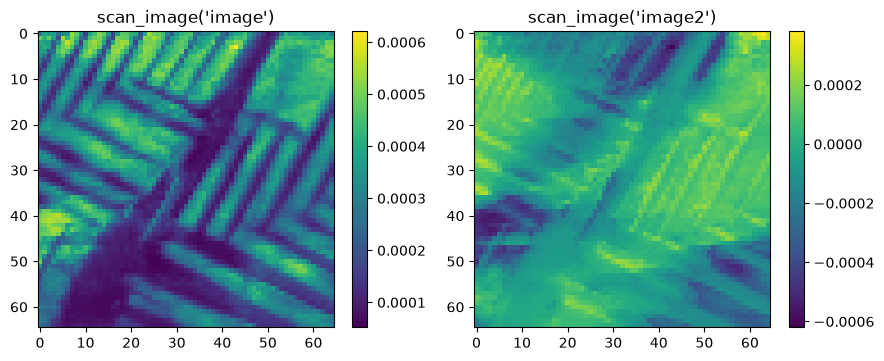

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, channel in zip(axes, scope.list_channels()):
    im = ax.imshow(scope.scan_image(channel), cmap="viridis")
    ax.set_title(f"scan_image({channel!r})")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 2. Moving the tip

`move_tip(x, y)` moves the tip to a physical coordinate in microns by
default (pass `units="px"` for pixel indices instead), and returns the
resulting `TipPosition`. Coordinates run from `(0, 0)` at the top-left pixel
to `(scan_size_um, scan_size_um)` at the bottom-right.

In [5]:
position = scope.move_tip(0.6, 0.6)
position

TipPosition(row=30, col=30, x_um=0.609375, y_um=0.609375)

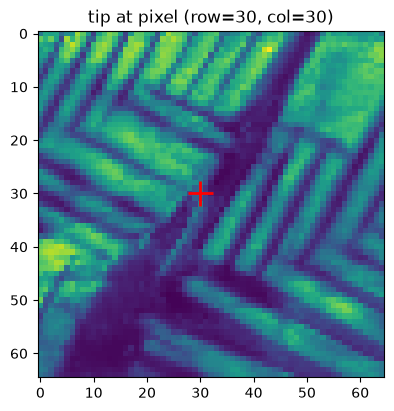

In [6]:
topo = scope.scan_image("image")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(topo, cmap="viridis")
ax.plot(position.col, position.row, "r+", markersize=18, markeredgewidth=2)
ax.set_title(f"tip at pixel (row={position.row}, col={position.col})")
plt.show()

## 3. Local spectroscopy

`spectroscopy()` measures at the tip's current position and returns
`(voltage, response)` -- the excitation voltage waveform paired with the
recorded piezoresponse loop at that pixel. `voltage_source` tells you
whether that voltage was actually recorded in the dataset (`"recorded"`) or
synthesized because the file didn't include one (`"synthesized"`); see the
package README for details.

voltage_source: recorded
voltage shape: (192,)  response shape: (192,)


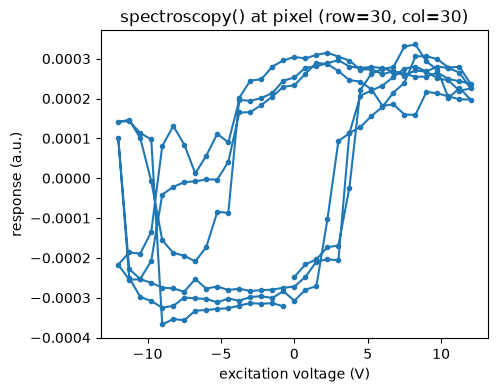

In [7]:
voltage, response = scope.spectroscopy()
print("voltage_source:", scope.voltage_source)
print("voltage shape:", voltage.shape, " response shape:", response.shape)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(voltage, response, marker=".")
ax.set_xlabel("excitation voltage (V)")
ax.set_ylabel("response (a.u.)")
ax.set_title(f"spectroscopy() at pixel (row={position.row}, col={position.col})")
plt.show()

`spectroscopy(x, y)` can move the tip and measure in one call. Here we
sweep a few points along a horizontal line and overlay their response
loops.